# MACHINE LEARNING
## Tema: Classificação de objetos celestes



Nesse projeto haverá a construção de um modelo de classificação multiclasse capaz de prever a classe de um objeto celeste (dentre as categorias `STAR`, `GALAXY` ou `QSO`) a partir de características fotométricas e espectroscópicas coletadas pelo telescópio do **Sloan Digital Sky Survey (SDSS)**. Acompanhará também a entrega toda a análise e tratamento dos dados respectivos.

## Dataset

**Stellar Classification Dataset - SDSS17**

Retirado de: [Kaggle - fedesoriano/stellar-classification-dataset-sdss17](https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17)

O dataset contém 100.000 observações de objetos celestes, cada uma descrita por 17 atributos (coordenadas, magnitudes em 5 filtros de luz, redshift, metadados de coleta) e uma coluna alvo (`class`) com 3 categorias possíveis.

**Por que dessa escolha?**


*   Problema multiclasse
*   Alto volume de dados
*   Fenômeno interpretável e verificável
*   Curiosidade





## Importação de bibliotecas

In [1]:
# bibliotecas para manipulação de dados
import numpy as np
import pandas as pd

# bibliotecas para visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns

# bibliotecas para modelagem
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
)

sns.set_theme(style="whitegrid") # para definir o estilo visual dos gráficos (deixa o fundo branco)
pd.set_option("display.max_columns", None) # seta o pandas para não "truncar" a exibição do dataframe quando utilizado

## Carregamento dos dados (importar o dataset e definir o dataframe)

In [2]:
# aqui utilizo o kagglehub para baixar o dataset diretamente do kaggle, como foi feito nas aulas do dojo
import kagglehub
import os

# baixa o dataset e retorna o caminho onde foi salvo, para conferir
path = kagglehub.dataset_download("fedesoriano/stellar-classification-dataset-sdss17")
print("Arquivos disponíveis:", os.listdir(path))

100%|██████████| 6.89M/6.89M [00:00<00:00, 78.9MB/s]

Extracting files...


Arquivos disponíveis: ['star_classification.csv']


In [3]:
# criação do dataframe (df)
df = pd.read_csv(os.path.join(path, "star_classification.csv"))
df.head()

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


## Exploração dos dados

Seguindo o passo a passo, é bom, antes de qualquer modelagem, entender a estrutura do dataset.

In [4]:
df.shape

(100000, 18)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   obj_ID       100000 non-null  float64
 1   alpha        100000 non-null  float64
 2   delta        100000 non-null  float64
 3   u            100000 non-null  float64
 4   g            100000 non-null  float64
 5   r            100000 non-null  float64
 6   i            100000 non-null  float64
 7   z            100000 non-null  float64
 8   run_ID       100000 non-null  int64  
 9   rerun_ID     100000 non-null  int64  
 10  cam_col      100000 non-null  int64  
 11  field_ID     100000 non-null  int64  
 12  spec_obj_ID  100000 non-null  float64
 13  class        100000 non-null  object 
 14  redshift     100000 non-null  float64
 15  plate        100000 non-null  int64  
 16  MJD          100000 non-null  int64  
 17  fiber_ID     100000 non-null  int64  
dtypes: float64(10), int64(7),

In [6]:
# verificando valores nulos: o retorno demonstra que não há nenhum valor nulo nas colunas
df.isnull().sum()

,0
obj_ID,0
alpha,0
delta,0
u,0
g,0
r,0
i,0
z,0
run_ID,0
rerun_ID,0


In [7]:
# verificando linhas duplicadas: o retorno demonstra que não há linhas duplicadas
df.duplicated().sum()


np.int64(0)

In [8]:
# estatísticas descritivas das variáveis numéricas
df.describe().T # usando .T para inverter linhas e colunas e deixar melhor visível


,count,mean,std,min,25%,50%,75%,max
obj_ID,100000.0,1.237665e+18,8.438560e+12,1.237646e+18,1.237659e+18,1.237663e+18,1.237668e+18,1.237681e+18
alpha,100000.0,1.776291e+02,9.650224e+01,5.527828e-03,1.275182e+02,1.809007e+02,2.338950e+02,3.599998e+02
delta,100000.0,2.413530e+01,1.964467e+01,-1.878533e+01,5.146771e+00,2.364592e+01,3.990155e+01,8.300052e+01
u,100000.0,2.198047e+01,3.176929e+01,-9.999000e+03,2.035235e+01,2.217914e+01,2.368744e+01,3.278139e+01
g,100000.0,2.053139e+01,3.175029e+01,-9.999000e+03,1.896523e+01,2.109983e+01,2.212377e+01,3.160224e+01
r,100000.0,1.964576e+01,1.854760e+00,9.822070e+00,1.813583e+01,2.012529e+01,2.104478e+01,2.957186e+01
i,100000.0,1.908485e+01,1.757895e+00,9.469903e+00,1.773228e+01,1.940514e+01,2.039650e+01,3.214147e+01
z,100000.0,1.866881e+01,3.172815e+01,-9.999000e+03,1.746068e+01,1.900460e+01,1.992112e+01,2.938374e+01
run_ID,100000.0,4.481366e+03,1.964765e+03,1.090000e+02,3.187000e+03,4.188000e+03,5.326000e+03,8.162000e+03
rerun_ID,100000.0,3.010000e+02,0.000000e+00,3.010000e+02,3.010000e+02,3.010000e+02,3.010000e+02,3.010000e+02


**ATENÇÃO:** ao olhar o output do comando `describe()`, é possível reparar que as colunas `u`, `g` e `z` apresentam um valor mínimo de aproximadamente **-9999**, o que é fisicamente impossível para uma magnitude astronômica, já que valores reais ficam entre 10 e 30. Após fazer uma pesquisa, descobri que esse é, muito provavelmente, um **valor sentinela**, usado pelo telescópio para indicar erro de leitura. Por conta disso (e do seu papel desruptivo na hora de montar gráficos e interpretar informações), ele precisará ser tratado na etapa de limpeza.

Fonte a respeito de **valores sentinela** no Data Science Academy:

[Guia Definitivo Para o Tratamento de Valores Ausentes em Data Science – Anatomia dos Valores Ausentes](https://blog.dsacademy.com.br/guia-definitivo-para-o-tratamento-de-valores-ausentes-em-data-science-anatomia-dos-valores-ausentes/#:~:text=N%C3%BAmeros%20Improv%C3%A1veis%3A%20Valores%20como%20%2D999%20ou%209999%20s%C3%A3o%20frequentemente%20usados%20em%20datasets%20mais%20antigos%20como%20marcadores%20de%20aus%C3%AAncia)

É interessante mencionar que essa observação("insight") não veio do nada. Antes de iniciar o projeto final de modelagem preditiva, eu tinha dado uma olhada e explorada nos datasets que pareciam interessantes, e o Stellar Classification foi um deles. Nessa, quando estava "brincando" com gráficos, a seguinte linha de código me causou confusão:

In [ ]:
sns.histplot(data=df, x='u', hue='class') # aqui cometi o erro de querer realizar o histograma sem antes analisar adequadamente os dados e por conta disso não realizar a limpeza corretamenta
# o resultado é que, apesar de não ter nenhum erro na linha de código, ela leva uma infinidade para executar e dá um gráfico irrelevante/não muito visualizável, e isso ocorre devido a presença
# do valor sentinela na variável u (-9999), que faz com que a máquina tente calcular o histograma com um range absurdamente grande

In [9]:
df['u'].describe() # aqui está mais visualizável o valor sentinela no mínimo de u

,u
count,100000.000000
mean,21.980468
std,31.769291
min,-9999.000000
25%,20.352353
50%,22.179135
75%,23.687440
max,32.781390


<Axes: xlabel='u', ylabel='Count'>

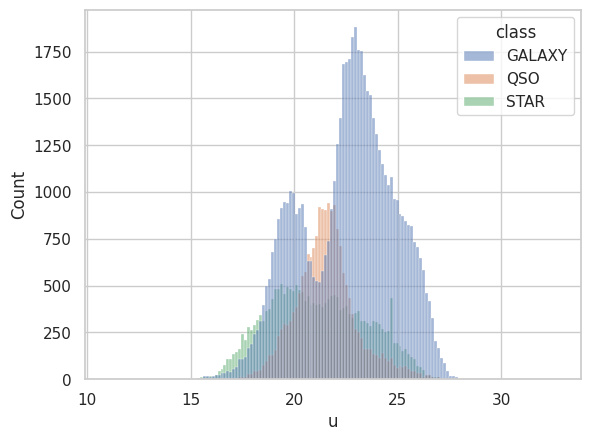

In [10]:
# realizando a limpeza, o código ficou o seguinte:
df_limpo = df[df['u'] > -1000]
sns.histplot(data=df_limpo, x='u', hue='class')

Voltando para a análise do dataset:

In [11]:
# distribuição das classes
df['class'].value_counts()


,count
class,
GALAXY,59445
STAR,21594
QSO,18961


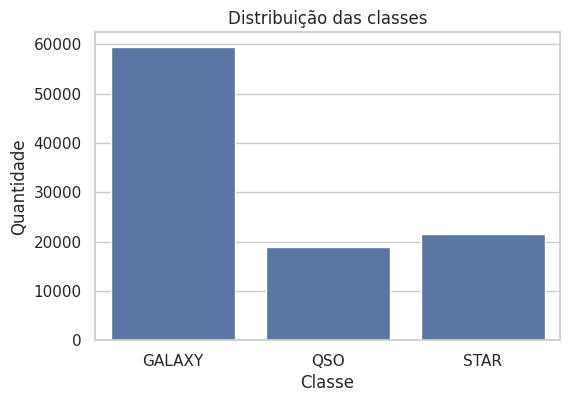

In [12]:
# visualização gráfica da distribuição das classes
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='class', ax=ax)
ax.set_title('Distribuição das classes')
ax.set_xlabel('Classe')
ax.set_ylabel('Quantidade')
plt.show()


Fazendo uma divisão básica por 100000 (número absoluto de objetos observados), chegamos na porcentagem aproximada de cada classe no dataset. A classe `GALAXY` é majoritária (59%), seguida de `STAR` (22%) e `QSO` (19%). O dataset é moderadamente desbalanceado. Isso é ruim porque pode ser como no exemplo utilizado no dojo: em uma análise se a pessoa "tem doença rara?", em um dataset que possui 91% das pessoas sem doença, um modelo que sempre prevê "não tem doença" já acertaria 91% das vezes, mesmo estando descalibrado. Aqui, um modelo "preguiçoso" que sempre prevê `GALAXY` acertaria 59% das vezes.

Por isso, esse fator reforça a importância de olharmos as métricas `precision`, `recall` e `f1-score` por classe na avaliação final do modelo que estamos criando, e não apenas a acurácia geral. Entrarei mais a fundo nesse tópico depois.

## Identificação das variáveis

O dataset vem do SDSS (Sloan Digital Sky Survey). As variáveis são confusas e possuem nomes não auto-explicativos, por isso a necessidade de descrever cada uma:

**Variáveis de identificação (sem valor preditivo real):**
- `obj_ID`, `run_ID`, `rerun_ID`, `cam_col`, `field_ID`, `spec_obj_ID`, `plate`, `MJD`, `fiber_ID`:
  identificadores internos do processo de coleta do telescópio (qual câmera, qual campo, qual
  placa do espectrógrafo, data da observação, etc). *Não têm relação causal com o tipo do objeto.*

**Coordenadas no céu:**
- `alpha`: ascensão reta (equivalente a "longitude" no céu)
- `delta`: declinação (equivalente a "latitude" no céu)

**Magnitudes (fotometria):**
- `u` (ultravioleta), `g` (verde), `r` (vermelho), `i` (infravermelho próximo), `z` (infravermelho distante)

*Quanto menor o valor, mais brilhante o objeto. Pode parecer relevante para o modelo mas na realidade é complicado fazer a distinção de classes a partir da magnitude por não saber se é porque o objeto possui um brilho maior, ou se é porque ele está mais próximo do observador (telescópio).*

**Redshift:**
- `redshift`: mede o quanto a luz do objeto foi deslocada para o vermelho devido à expansão do universo. Quanto maior o redshift, mais distante (e mais antigo) é o objeto. *Essa é possivelmente a variável mais relevante para o modelo.*

**Variáveis alvo (classes):**
- `class`: `STAR`, `GALAXY` ou `QSO` (quasar). *Essas são as classes que queremos prever a partir do modelo.*


## Limpeza dos dados

Como exemplificado anteriormente, tem-se de remover as linhas com valores sentinela (`-9999`) nas colunas `u`, `g` e `z`. Sem esse tratamento, esses valores distorceriam tanto os gráficos quanto o cálculo de correlação entre as variáveis.

In [ ]:
print("Linhas antes da limpeza:", df.shape[0])
df_limpo = df[(df['u'] > -1000) & (df['g'] > -1000) & (df['z'] > -1000)].copy()
print("Linhas depois da limpeza:", df_limpo.shape[0])

Linhas antes da limpeza: 100000
Linhas depois da limpeza: 99999


In [ ]:
# utilizando o describe() depois de remover os valores sentinela
df_limpo[['u', 'g', 'z']].describe().T

,count,mean,std,min,25%,50%,75%,max
u,99999.0,22.080679,2.251068,10.996230,20.35241,22.17914,23.687480,32.78139
g,99999.0,20.631583,2.037384,10.498200,18.96524,21.09993,22.123775,31.60224
z,99999.0,18.768988,1.765982,9.612333,17.46083,19.00460,19.921120,29.38374


## Análise exploratória univariada

Agora analisando como cada variável numérica se distribui, separando por classe com `hue='class'`.

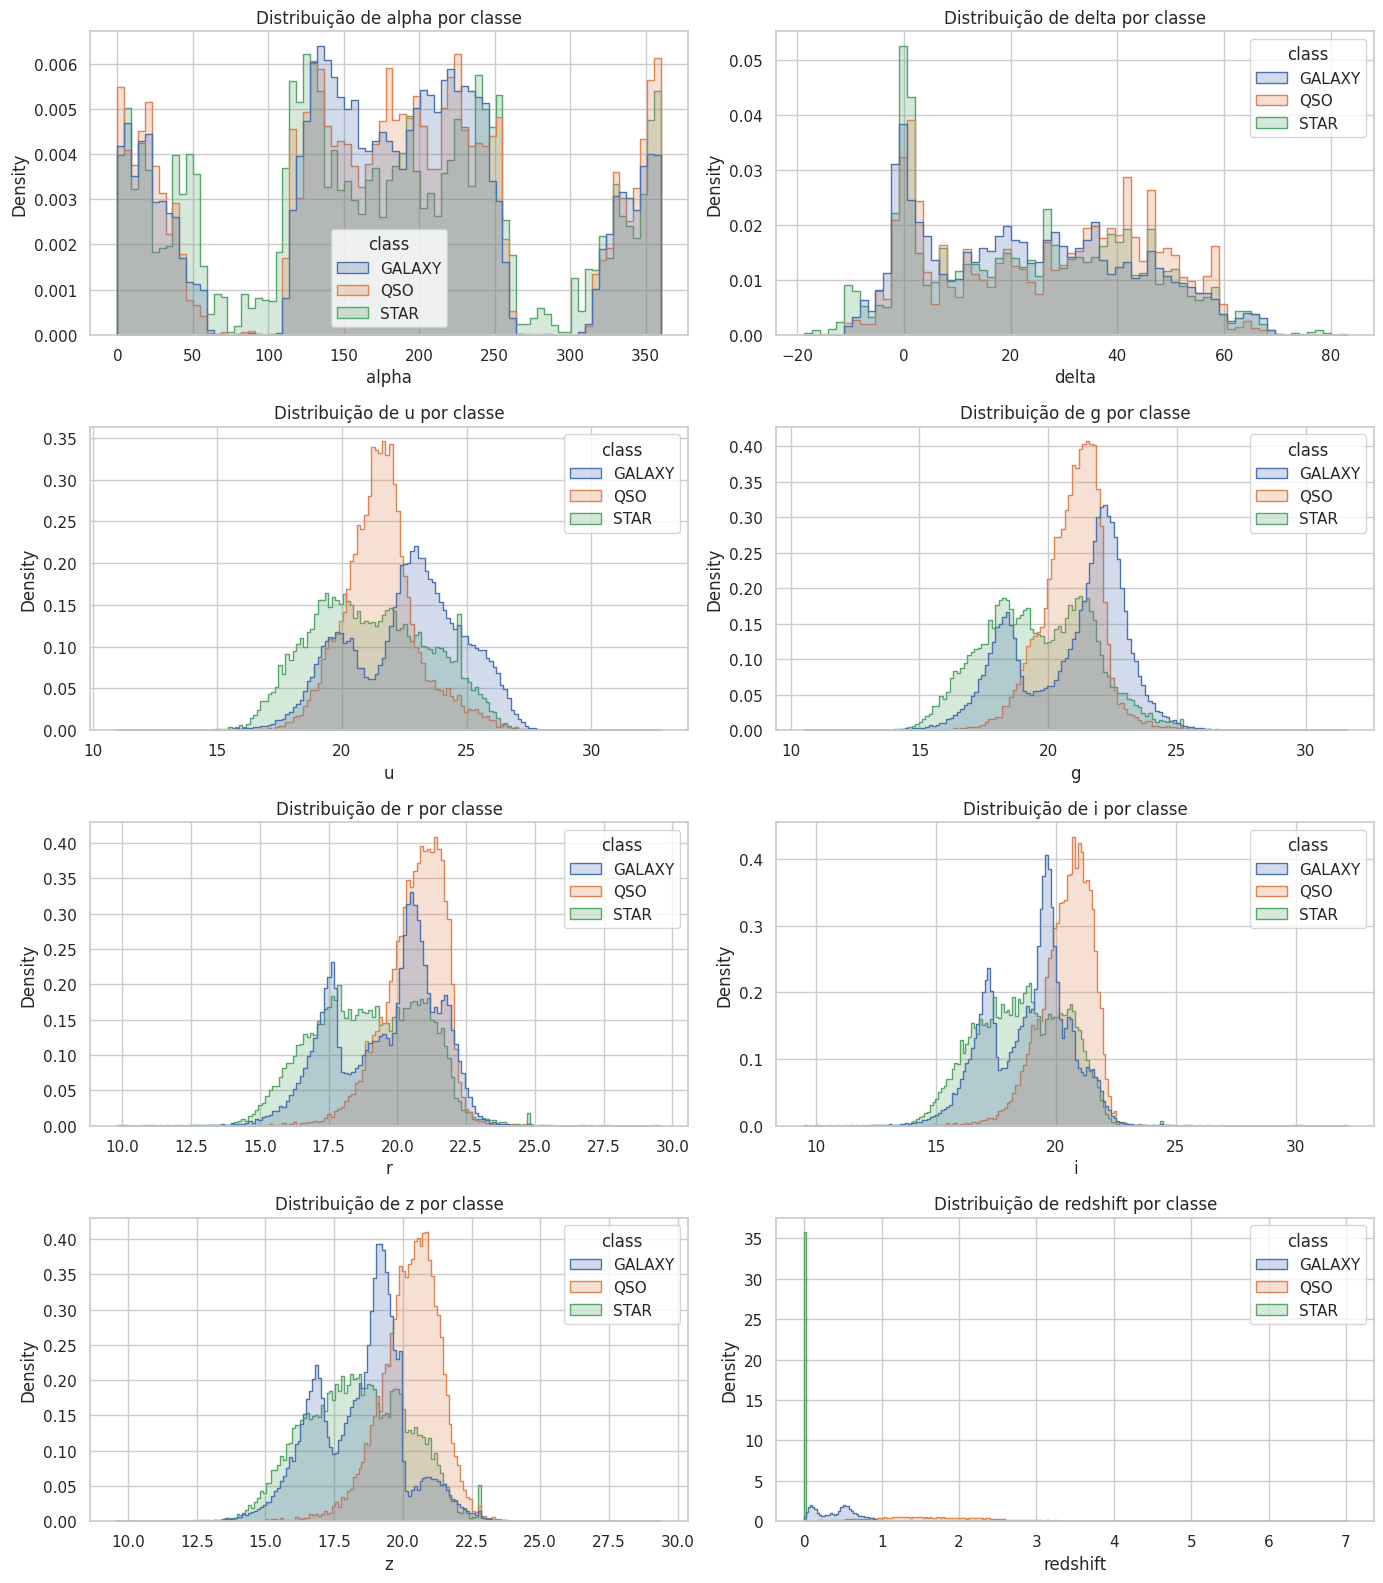

In [13]:
colunas_numericas = ['alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'redshift']

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for ax, col in zip(axes, colunas_numericas):
    sns.histplot(data=df_limpo, x=col, hue='class', ax=ax, element='step', stat='density', common_norm=False)
    ax.set_title(f'Distribuição de {col} por classe')

plt.tight_layout()
plt.show()


Os gráficos de distribuição de `alpha` e `delta` por classe confirmam o que tinha sido anteriormente: a posição do objeto no céu não tem relação com o tipo do objeto. Portanto, essas duas variáveis possuem **baixo poder descritivo**.

Sobre `u`, `g`, `r`, `i` e `z` (magnitudes/brilho), existe uma separação parcial, mas com **sobreposição considerável** entre as três classes em todas as variáveis. Nenhuma delas sozinha separa bem as classes, mas cada uma contribui um pouco.

Por outro lado, foi possível reparar que a distribuição de `redshift` é a que mostra a separação mais nítida entre as classes, uma vez que `STAR` fica concentrada quando redshift tende a 0, `GALAXY` fica numa faixa baixa-moderada, e `QSO` numa faixa bem mais ampla e alta. Isso já é um forte indício de que `redshift` será uma das **features mais importantes do modelo**.

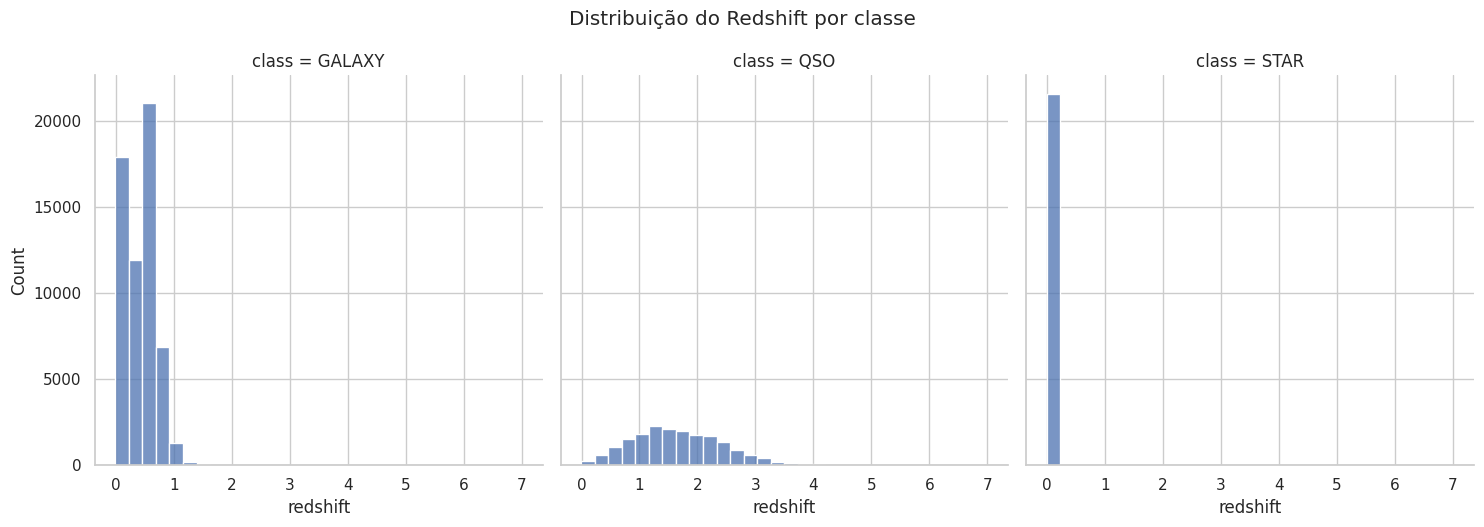

In [14]:
# dando uma olhada específica e unitária na distribuição de redshift por classe, agora em valores absolutos e em um gráfico mais visualizável
g = sns.displot(
    data=df_limpo,
    x='redshift',
    col='class',
    bins=30,
    facet_kws={'sharey': True}  # força a mesma escala no eixo Y nos 3 painéis
)
g.fig.suptitle('Distribuição do Redshift por classe', y=1.05)
plt.show()


## Análise bivariada e correlação

Agora é necessário olhar como pares de variáveis se relacionam e calcular a matriz de correlação para identificar possível redundância entre features, o que ajuda a decidiria quais manter no modelo.

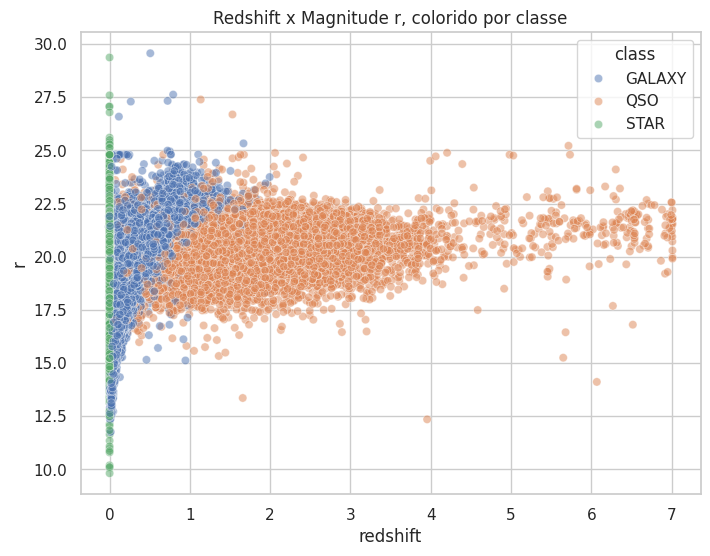

In [15]:
fig, ax = plt.subplots(figsize=(8, 6)) # agora criando um scatterplot combinando redshift e magnitude r
sns.scatterplot(data=df_limpo, x='redshift', y='r', hue='class', alpha=0.5, ax=ax)
ax.set_title('Redshift x Magnitude r, colorido por classe')
plt.show()


**INTERPRETAÇÃO 01:** `STAR` fica colada em redshift igual a 0, formando uma faixa espalhada por todos os valores de magnitude `r`. Isso releva que estrelas não têm redshift perceptível, e que sua magnitude varia (independente do redshift) dependendo do quão longe estão dentro da própria galáxia.

**INTERPRETAÇÃO 02:** `GALAXY` fica em uma faixa de `redshift` mais estreita (aproximadamente entre 0 a 1) e sua magnitude `r` fica entre 17 e 25, apesar de valores externos.

**INTERPRETAÇÃO 03:** a classe `QSO` se espalha por uma faixa de redshift muito mais ampla (vai de até perto de 0 para até 7), tendo predominância em valores de redshift maiores. Também é perceptível que a magnitude `r` dos quasares fica estável entre 17.5 e 23 (conforme visualizável no gráfico), independente do valor de redshift.

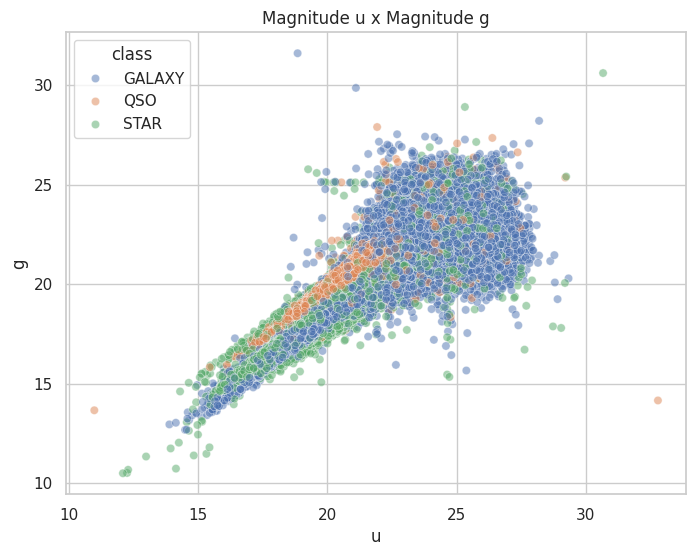

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6)) # aqui criando um scatterplot para compreender a correlação entre u e g
sns.scatterplot(data=df_limpo, x='u', y='g', hue='class', alpha=0.5, ax=ax)
ax.set_title('Magnitude u x Magnitude g')
plt.show()


Os pontos no gráfico forma uma diagonal clara, indicando uma **correlação forte** entre `u` e `g`, o que é uma constatação de que objetos mais brilhantes em um filtro devem ser brilhantes no outro também.

Nem toda combinação de variáveis separa bem as classes: enquanto no gráfico anterior pudemos ver a criação de três regiões bens distintas, mas a combinação das magnitudes não tem poder discriminativo o suficiente para separar as classes como redshift faz.

**O próximo passo aqui é fazer o heatmap de correlação. Manipulando os dados, algo curioso aconteceu:**

<Axes: >

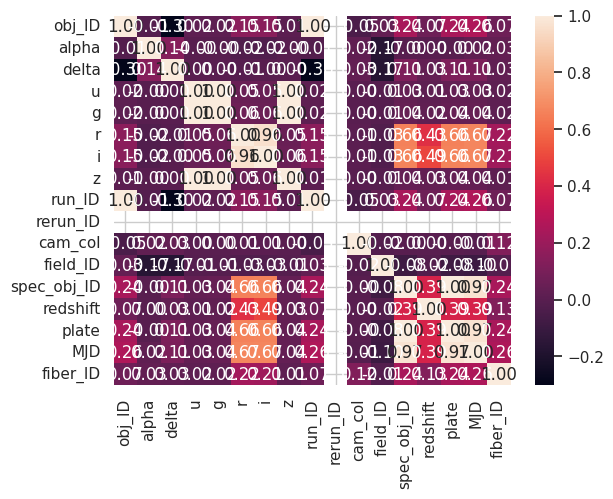

In [16]:
fig, ax = plt.subplots()
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f') # a primeira vez que fui fazer o heatmap isso aconteceu. o primeiro grande problema é a visibilidade

<Axes: >

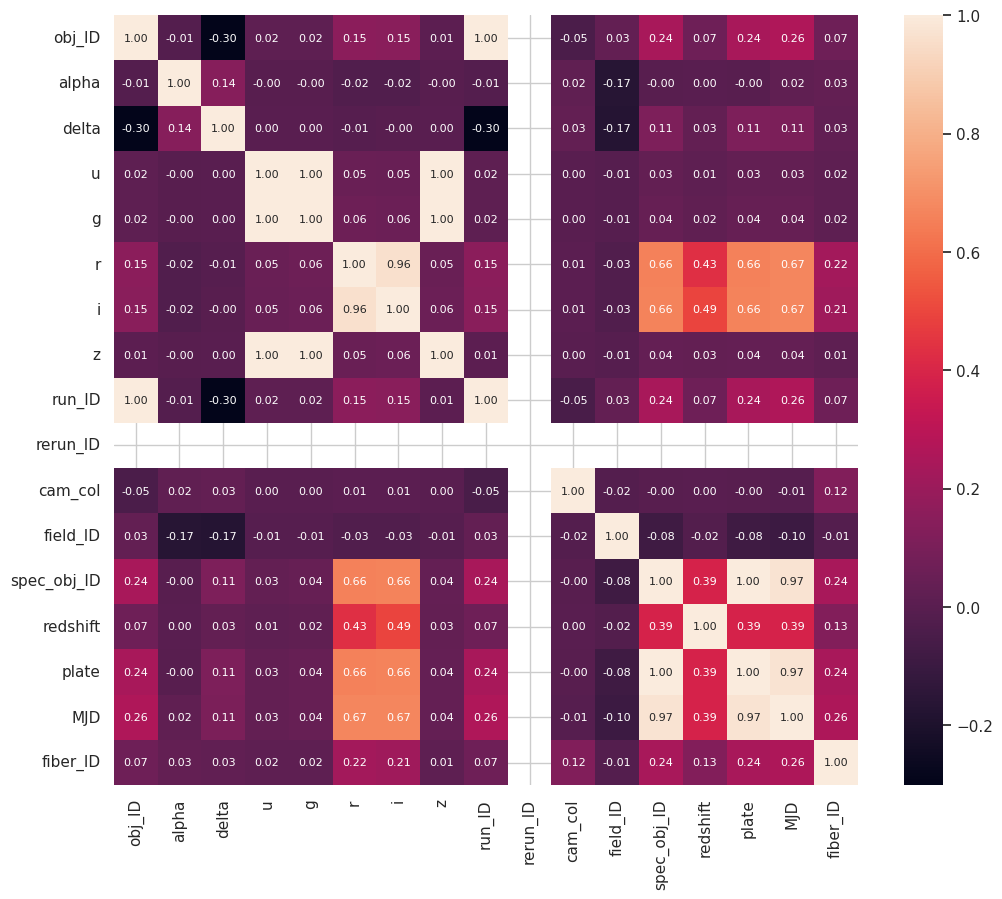

In [ ]:
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', annot_kws={'size': 8}) # com esse gráfico de agora, os dados estão mais visíveis (pela escala) mas ainda assim não está muito interpretável
# uma vez que existem múltiplos dados e correlações irrelevantes. além disso, é preciso tirar aqueles valores sentinelas para fazer a análise adequada

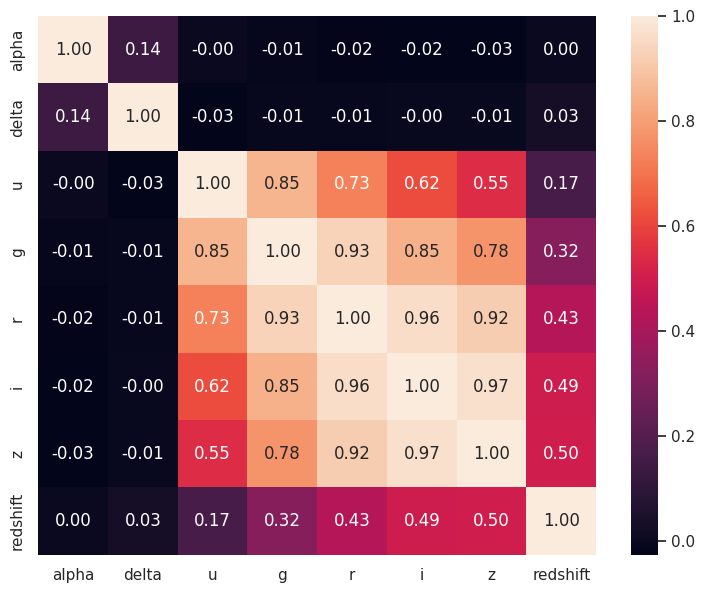

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df_limpo[colunas_numericas].corr()
sns.heatmap(corr, annot=True, fmt='.2f', ax=ax)
plt.show() # aqui nesse heatmap deixa-se o gráfico mais visível, utilizamos apenas as variáveis relevantes (retirando as de identificação), e também o uso de df_limpo garante a exclusão dos valores sentinela

**INTERPRETAÇÃO:**

- `r` e `i` têm correlação muito alta (~0.96), o que indica que carregam informação redundante entre si.
- `u`, `g`, `r`, `i`, `z` são todas fortemente correlacionadas entre si (pelo motivo mencionado anteriormente).
- `redshift` tem correlação apenas moderada com as magnitudes (mais forte com `z`, mais fraca com `u`), o que indica que ele carrega informação **complementar**, não redundante, em relação às magnitudes.
- `alpha` e `delta` (coordenadas no céu) não têm correlação relevante com nenhuma outra variável.


## Seleção das variáveis para o modelo

Com base em toda a análise dos dados e variáveis feita, vamos fazer a seleção das features:

- remover as colunas de metadados técnicos (`obj_ID`, `run_ID`, `rerun_ID`, `cam_col`, `field_ID`,
  `spec_obj_ID`, `plate`, `MJD`, `fiber_ID`) e das coordenadas (`alpha`, `delta`), pois não possuem nenhuma relação com a classe do objeto.
- manter as as magnitudes (`u`, `g`, `r`, `i`, `z`) e o `redshift`, já que essas são as variáveis com potencial preditivo real.

In [17]:
features_selecionadas = ['u', 'g', 'r', 'i', 'z', 'redshift'] # aqui definimos as features certas
target = 'class'

X = df_limpo[features_selecionadas]
y = df_limpo[target]

X.head()

,u,g,r,i,z,redshift
0,23.87882,22.27530,20.39501,19.16573,18.79371,0.634794
1,24.77759,22.83188,22.58444,21.16812,21.61427,0.779136
2,25.26307,22.66389,20.60976,19.34857,18.94827,0.644195
3,22.13682,23.77656,21.61162,20.50454,19.25010,0.932346
4,19.43718,17.58028,16.49747,15.97711,15.54461,0.116123


## Preparação dos dados

Como o alvo (`class`) é uma variável categórica em formato texto, o próximo passo é codificar numericamente com `LabelEncoder`.

Em seguida, dividimos os dados em treino e teste de forma estratificada, garantindo que a proporção das 3 classes se mantenha em ambos os conjuntos — importante já que o dataset é moderadamente desbalanceado e necessário para evitar aquele problema de criar um modelo errôneo e com avaliação "preguiçosa".

In [20]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Classes:", list(le.classes_)) # le.classes_ guarda a lista de categorias únicas que LabelEncoder encontrou
print("Codificação:", dict(zip(le.classes_, le.transform(le.classes_)))) # aqui uso o print pra mostrar de forma clara qual texto virou número
# ou seja, 0 significa GALAXY, 1 significa QSO e 2 significa STAR

Classes: ['GALAXY', 'QSO', 'STAR']
Codificação: {'GALAXY': np.int64(0), 'QSO': np.int64(1), 'STAR': np.int64(2)}


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
) # aqui é onde está sendo feita a divisão, como dito, do dataset em duas partes: uma para o modelo aprender e outra escondida para ser utilizada apenas para a hora de avaliá-lo

print("Tamanho treino:", X_train.shape[0])
print("Tamanho teste:", X_test.shape[0]) # aqui, confirmando a divisão feita de 80% para 20%


Tamanho treino: 79999
Tamanho teste: 20000


## 10. Modelo: Árvore de Decisão

Escolhi a Árvore de Decisão como algoritmo principal pela interpretabilidade (ver exatamente como o modelo funciona e seu raciocínio) e por também não exigir padronização das variáveis mesmo que em escalas diferentes (o que eu teria que fazer caso trabalhasse com KNN por exemplo). Inicia-se, assim, com um modelo baseline usando `criterion='entropy'` e parâmetros padrão, para termos uma referência antes de fazer o tuning de hiperparâmetros.

In [22]:
clf_base = DecisionTreeClassifier(criterion='entropy', random_state=42) # cria o modelo de árvore de decisão, define o critério para escolha de nós como a redução da entropia
clf_base.fit(X_train, y_train) # aqui é iniciamos a etapa de treino, onde o modelo vai aprender os padrões e "montar a árvore de decisões"

y_pred_base = clf_base.predict(X_test) # aqui é onde o modelo lida com dados "novos"
print("Acurácia baseline:", accuracy_score(y_test, y_pred_base))
print()
print(classification_report(y_test, y_pred_base, target_names=le.classes_)) # aqui são gerados precision, recall, f1-score e support, por classe, essencial considerando que o dataset é DESBALANCEADO


Acurácia baseline: 0.9692

              precision    recall  f1-score   support

      GALAXY       0.97      0.97      0.97     11889
         QSO       0.92      0.92      0.92      3792
        STAR       1.00      1.00      1.00      4319

    accuracy                           0.97     20000
   macro avg       0.96      0.96      0.96     20000
weighted avg       0.97      0.97      0.97     20000



A acurácia de 96,92%, sem ajuste de hiperparâmetros é um resultado bem forte e acaba sendo um resultado da feature `redshift` ser tão discriminativa. `QSO`, como imaginado, é a classe que mais se confunde com as outras, especialmente `GALAXY`.

## 11. Avaliação com Validação Cruzada Estratificada

Antes de confiar num único treino, é necessário usar `StratifiedKFold` para ter uma estimativa mais robusta da performance do modelo, mantendo a proporção das classes em cada fold.

In [23]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # divide o dataset em 5 folds, embaralha os dados e fixa a semente de "aleatoriedade"

scores = cross_val_score(clf_base, X, y_encoded, cv=kf, scoring='accuracy') # aqui é quando os folds vão ser pegos, utilizados para treinar e avaliar/testar

print("Acurácia por fold:", scores) # o resultado próximo aqui já indica que o modelo não depende de "sorte"
print(f"Acurácia média: {scores.mean():.4f} (+/- {scores.std():.4f})")


Acurácia por fold: [0.9657     0.9668     0.9672     0.967      0.96669833]
Acurácia média: 0.9667 (+/- 0.0005)


A validação cruzada é importante por garantir, com 5 divisões diferentes, que o modelo não dependa do acaso para ser efetivo.

## 12. Hyperparameter Tuning (GridSearchCV)

Agora, o passo é usar `GridSearchCV` para buscar a melhor combinação de hiperparâmetros da Árvore de Decisão,
testando diferentes valores de `criterion`, `max_depth` e `min_samples_leaf`, por serem os principais parâmetros que controlam o trade-off entre overfitting e underfitting, como foi mostrado no dojo.

In [24]:
param_grid = {
    'criterion': ['gini', 'entropy'], # qual métrica usar para decidir as decisões da árvore, gini ou entropia
    'max_depth': [3, 5, 7, 10, None], # controle para overfitting
    'min_samples_leaf': [1, 5, 10, 20], # controle para underfitting
} # 2 x 5 x 4 = 40 combinações diferentes para testar

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42), # o modelo que será testado
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), # rodando uma validação cruzada de 5 folds
    scoring='accuracy',
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)

print("Melhores hiperparâmetros encontrados:")
print(grid_search.best_params_)
print(f"Melhor acurácia média (CV): {grid_search.best_score_:.4f}")


Melhores hiperparâmetros encontrados:
{'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 20}
Melhor acurácia média (CV): 0.9756


In [ ]:
melhor_modelo = grid_search.best_estimator_ # aqui salvamos o modelo já treinado com a melhor combinação de hiperparâmetros para utilizar esse objeto daqui para frente na avaliação final


## 13. Avaliação final do modelo

Agora, com o melhor modelo encontrado pelo `GridSearchCV`, é possível finalmente avaliá-lo no conjunto de teste (aqueles 20000 exemplos que ficaram de fora no processo de treinamento, dados nunca vistos antes pelo modelo).

In [ ]:
y_pred = melhor_modelo.predict(X_test)

print("Acurácia final:", accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=le.classes_)) # interessante ver a melhoria de 1% para GALAXY e 2% para QSO


Acurácia final: 0.9778

              precision    recall  f1-score   support

      GALAXY       0.98      0.99      0.98     11889
         QSO       0.96      0.93      0.94      3792
        STAR       1.00      1.00      1.00      4319

    accuracy                           0.98     20000
   macro avg       0.98      0.97      0.97     20000
weighted avg       0.98      0.98      0.98     20000



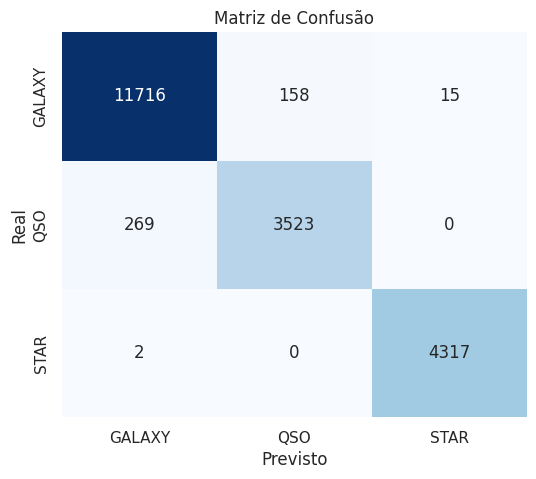

In [ ]:
cm = confusion_matrix(y_test, y_pred) # aqui é criada uma matriz para verificar como o modelo se confunde, e com o que se confunde

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()

## 14. Importância das features

A Árvore de Decisão permite verificar quais variáveis mais contribuíram para as decisões do modelo. `redshift` aparece como a mais importante, confirmando o que havia sido observado na análise exploratória.

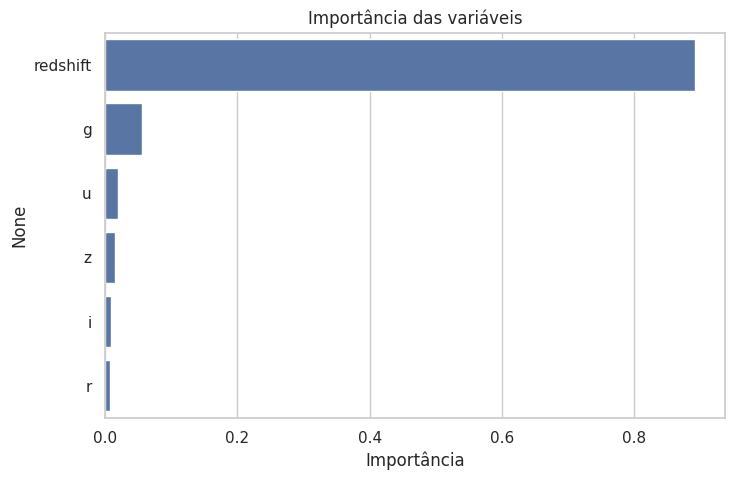

,0
redshift,0.892680
g,0.055699
u,0.020106
z,0.015785
i,0.008790
r,0.006940


In [ ]:
importancias = pd.Series(melhor_modelo.feature_importances_, index=features_selecionadas)
importancias = importancias.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=importancias.values, y=importancias.index, ax=ax, orient='h')
ax.set_title('Importância das variáveis')
ax.set_xlabel('Importância')
plt.show()

importancias


## 15. Visualização da Árvore

Por fim, podemos utilizar o `graphviz`, que foi demonstrado no dojo, para fazer uma visualização gráfica da Árvore de Decisão e seus múltiplos "ramos".

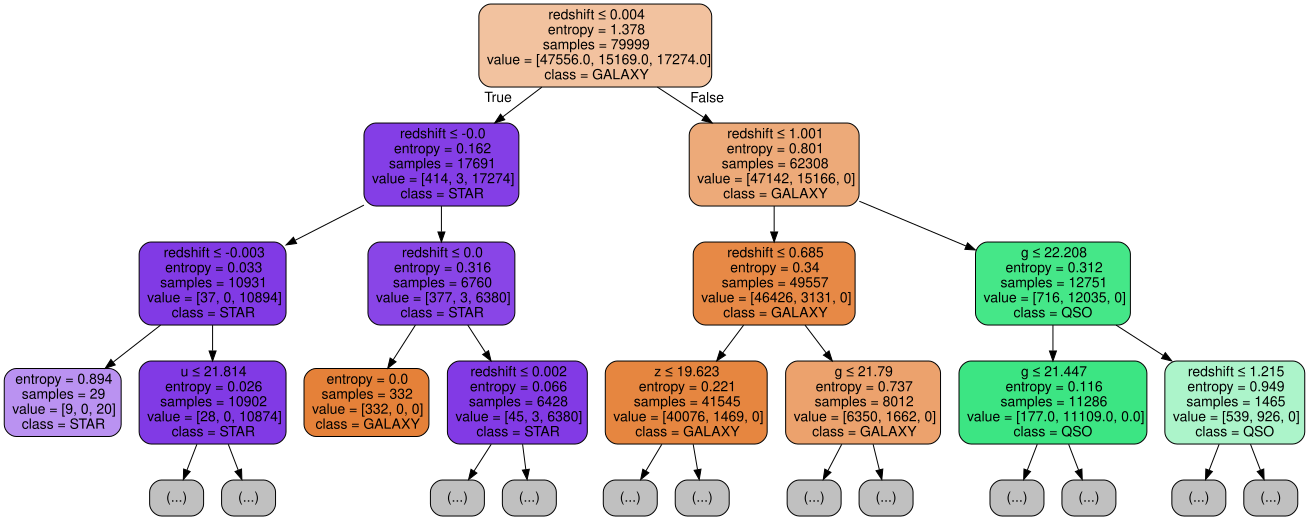

In [ ]:
from sklearn.tree import export_graphviz
import graphviz

dot_data = export_graphviz(
    melhor_modelo,
    max_depth=3,
    feature_names=features_selecionadas,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    special_characters=True
)
graph = graphviz.Source(dot_data)
graph


## 16. Conclusões do projeto

O dataset de classificação estelar do SDSS17 apresenta 3 classes moderadamente desbalanceadas (`GALAXY` > `STAR` > `QSO`), o que reforçou a importância de avaliar o modelo com métricas por classe (precisão, recall, f1-score), e não apenas com acurácia geral.


---


Durante a análise do dataset, foram identificados e removidos valores sentinela (`-9999`) presentes nas colunas `u`, `g` e `z`, essenciais para não distorcer os gráficos e a matriz de correlação. Os valores sentinela funcionam como outliers que desconfiguram/dificultam a análise.


---


A variável **`redshift`** se mostrou, tanto na análise exploratória dos dados quanto na importância de variáveis do modelo treinado, a feature com maior poder discriminativo entre as 3 classes — resultado fisicamente coerente, já que redshift está diretamente ligado à distância do objeto, um fator determinante para diferenciar estrelas (próximas), galáxias e quasares (muito distantes).


---


Foi identificada redundância entre `r` e `i` (correlação ~0.96), o que poderia ser explorado em trabalhos mais complexos através de remoção de uma dessas variáveis ou de técnicas de redução de dimensionalidade.


---


O `GridSearchCV` foi usado para buscar a melhor combinação de `criterion`, `max_depth` e `min_samples_leaf`, evitando tanto overfitting (árvore muito profunda) quanto underfitting.


---


O modelo final atingiu acurácia de aproximadamente **0,98** no conjunto de teste, com bom desempenho em todas as 3 classes conforme o `classification_report`.

### Pontos a se pensar
- Testar outros algoritmos de classificação (Random Forest, SVM) e comparar performance.
- Explorar features derivadas ("cores" astronômicas, como `u - g`).
- Investigar se a remoção de `r` ou `i` (dada a alta correlação entre elas) afeta a performance.
